# Implementation of Lucas Kanade's Optical Flow

Optical flow is the motion of objects between consecutive frames of sequence. Since, each video is a sequence of images every two consecutive frames can be given to optical flow algorithm which calculates the displacements of features spatially.  
* The idea behind Lucas Kanade is to find movement of pixels in the 2 frames by finding the least square solution on a vector using the gradient in the x & y directions which would help predict the movement of the pixels.  
* We use the computed flow to detect, segment and track objects in videos.

### Assumptions of Optical Flow
Since the two consecutive frames captured from a video are taken with negligible time difference, we can assume :-  

1. The displacement of any object is not large.
2. The intensity of the object doesn't change.  
3. Neighboring pixels(containing the object) move in the same direction.  

* Using the above three assumptions, we calculate the motion of the objects in the given frames.

# Import libraries and load images
We begin by importing the required libraries and loading two consecutive grayscale images for optical flow computation.  


In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Load the two consecutive frames as grayscale images
frame1 = cv2.imread('basketball1.png', cv2.IMREAD_GRAYSCALE)
frame2 = cv2.imread('basketball2.png', cv2.IMREAD_GRAYSCALE)

In [3]:
# Normalize images to the range [0, 1]
frame1 = frame1 / 255.0
frame2 = frame2 / 255.0

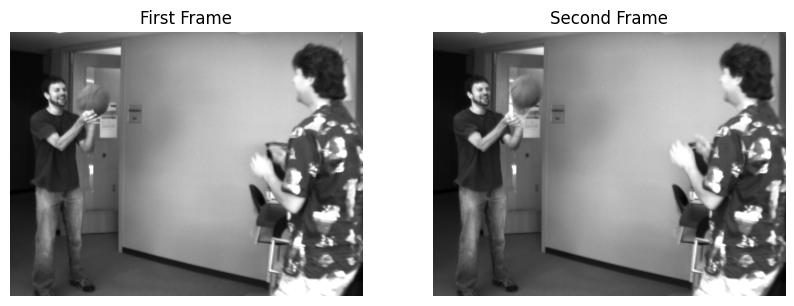

In [4]:
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(frame1, cmap='gray')
plt.title("First Frame")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(frame2, cmap='gray')
plt.title("Second Frame")
plt.axis('off')

plt.show()

# Detect good features to track

* It is important to figure out which features to track. The object's Corners make a very good feature set that would dictate the movement of the object.  
* To detect the corner's we can use Harris Corner Detector approach but for now, we use `cv2.goodFeaturesToTrack()` api call to obtain corners by "Shi Tomasi's approach" since it performs better.

* We identify feature points in the first image, focusing the calculations on distinctive points instead of processing all pixels.

In [5]:
# Detect good features to track in the first frame
num_corners = 100
quality_level = 0.01
min_distance = 5

features = cv2.goodFeaturesToTrack(
    (frame1 * 255).astype(np.uint8),    # Input image (scaled back to 8-bit)
    maxCorners = num_corners,           # Maximum number of corners to return
    qualityLevel = quality_level,       # Minimum accepted quality of corners
    minDistance = min_distance          # Minimum distance between detected corners
)

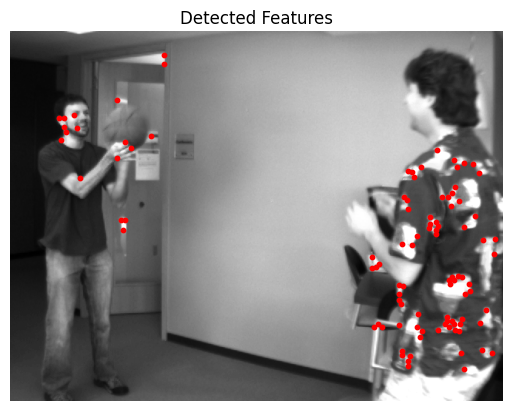

In [6]:
# Visualize detected features
plt.imshow(frame1, cmap='gray')
plt.scatter(features[:, 0, 0], features[:, 0, 1], color='red', s=10)
plt.title("Detected Features")
plt.axis('off')
plt.show()

# Calculate image gradients using convolution kernels

Compute the gradients along *x*, *y*, and *t* (time) directions for optical flow calculation.  

In [7]:
# Define convolution kernels for gradients
kernel_x =  np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1] ])    # Gradient in X
kernel_y =  np.array([
    [-1, -2, -1],
    [ 0,  0,  0],
    [ 1,  2,  1]
])   # Gradient in Y
kernel_t =  np.array([[-1], [0], [1]])   # Gradient in Time

In [8]:
# Compute image gradients
Ix = cv2.filter2D(frame1, -1, kernel_x)              #Gradient over X
Iy = cv2.filter2D(frame1, -1, kernel_y)              #Gradient over Y
It = cv2.filter2D(frame2, -1, kernel_t) - cv2.filter2D(frame1, -1, kernel_t)  #Gradient over Time

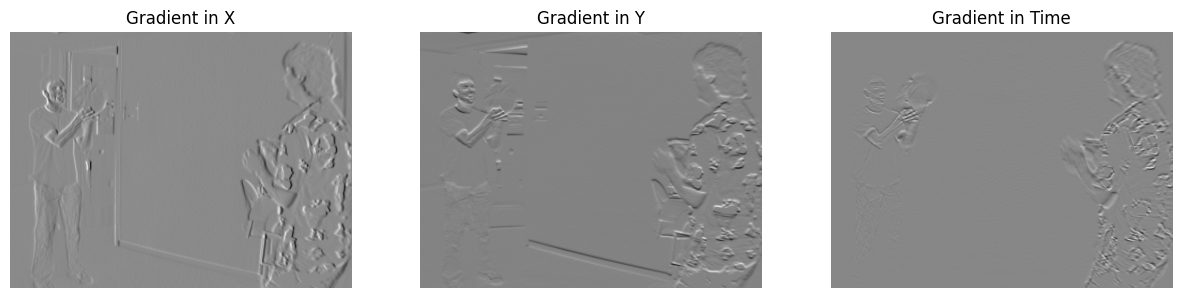

In [9]:
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(Ix, cmap='gray')
plt.title("Gradient in X")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(Iy, cmap='gray')
plt.title("Gradient in Y")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(It, cmap='gray')
plt.title("Gradient in Time")
plt.axis('off')

plt.show()

# Calculate optical flow using Lucas-Kanade equation

* Iterate through detected features to compute flow vectors \(u\) and \(v\).  
* From the assumptions stated above, we can consider that :  
I(x, y, t) = I(x + dx, y + dy, t + dt)  
Where, I(x,y,t) is the intensity at pixel (x,y) at time t  
and I( x+dx, y+dy, t+dt) is the same intensity of displaced corner after time dt.  
* By expanding the RHS with Taylor's series, we can cut down common terms and neglect the higher order derivatives since they become negligible.  
* So, we get :  
f_x * u + f_y * v + f_t = 0  
Where, f_x is gradient w.r.to X direction  
f_y is gradient w.r.to Y direction  
f_t is change w.r.to time  


In [10]:
# Initialize flow vectors
u = np.zeros(frame1.shape)
v = np.zeros(frame1.shape)

In [12]:
# Window size for neighborhood
window_size = 5
w = window_size // 2

for feature in features:                # for every corner
    j, i = feature.ravel().astype(int)

    # Extract neighborhood gradients
    Ix_window = Ix[i-w : i+w+1, j-w : j+w+1].flatten()
    Iy_window = Iy[i-w : i+w+1, j-w : j+w+1].flatten()
    It_window = It[i-w : i+w+1, j-w : j+w+1].flatten()

    # Form matrices A and b
    A = np.vstack((Ix_window, Iy_window)).T
    b = np.reshape(It_window, (It_window.shape[0],1))

    A_t = A.T

    # Solve for optical flow using least squares
    flow =  np.linalg.pinv(A_t @ A) @ A_t @ -b         # Solve for (u,v)
    u[i,j] = flow[0]  # Horizontal flow component
    v[i,j] = flow[1]  # Vertical flow component

<ipython-input-12-484052028612>:21: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  u[i,j] = flow[0]  # Horizontal flow component
<ipython-input-12-484052028612>:22: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  v[i,j] = flow[1]  # Vertical flow component


* Here we can't get u,v with single equation. So, we use the 3rd assumption stated above (neighbouring pixels would move similarly).  

* Hence, with a window of pixels (of size n), we get n * n equations that would help us solve for (u,v).  

* After getting (u,v), we plot the results.

In [13]:
print(A.shape)
print(b.shape)

(25, 2)
(25, 1)


# Visualize the optical flow vectors  
Plot the flow vectors on the original image for visualization.

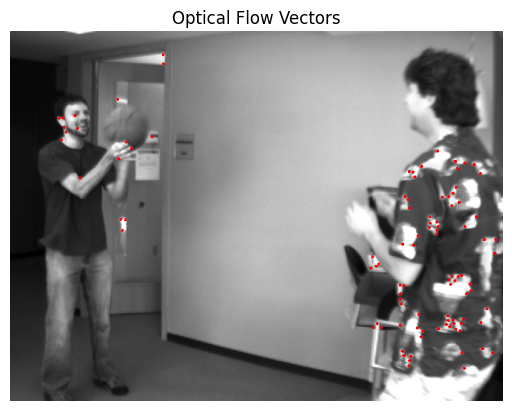

In [14]:
# Visualize optical flow
plt.imshow(frame1, cmap='gray')
for feature in features:
    j, i = feature.ravel().astype(int)
    plt.arrow(j, i, v[i, j]*5, u[i, j]*5, color='red', head_width=3, head_length=1.5)

plt.title("Optical Flow Vectors")
plt.axis('off')
plt.show()

# Lucas-Kanade Parameters

In [15]:
# Load the two consecutive frames as grayscale images
frame1 = cv2.imread('basketball1.png', cv2.IMREAD_GRAYSCALE)
frame2 = cv2.imread('basketball2.png', cv2.IMREAD_GRAYSCALE)

In [16]:
# Parameters for Lucas-Kanade
'''
winSize=(15, 15): Size of the window used for computing motion in each region.
maxLevel=2: Number of pyramid levels for multiscale tracking.
criteria: Stopping criteria for the iterative solver. '''

lk_params = dict(winSize=(15, 15), maxLevel=2,
                 criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 10, 0.03))

# Optical Flow Calculation

In [17]:
'''
calcOpticalFlowPyrLK() takes the two frames and detected points 'features'
returns:
p1: The new positions of the tracked points in frame2.
st: Status array (1 if the point was successfully tracked, 0 otherwise).
err: Tracking error for each point. '''

p1, st, err = cv2.calcOpticalFlowPyrLK(frame1, frame2, features, None, **lk_params)

# Visualizing the Motion Vectors

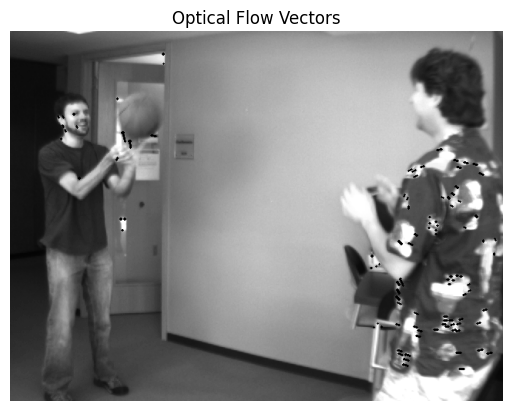

In [18]:
# Visualize the motion
for i, (new, old) in enumerate(zip(p1, features)):
    a, b = new.ravel()
    c, d = old.ravel()

    # Convert coordinates to integers
    a, b = int(a), int(b)
    c, d = int(c), int(d)

    # Draws arrows from old positions (c, d) to new positions (a, b) to indicate motion.
    frame2 = cv2.arrowedLine(frame2, (c, d), (a, b), (0, 255, 0), 2)

# Show the result using Matplotlib
plt.imshow(frame2, cmap='gray')
plt.axis('off')
plt.title("Optical Flow Vectors")
plt.show()